# code_027 · Learning from labelled examples

**Book:** section 6.1. These are synthetic mechanism experiments, not observed structural performance, safety assessment, a causal study or an estimator leaderboard. Each experiment states which cases are unseen and which outcomes are available. Fits and preprocessing use training observations only. Development curves support diagnosis; final outcomes are opened only after the stated rule is fixed. Constructed identities and stress cases are not held-out population estimates.

Restart and run all cells. All imports, helpers and data generation are here; no ordinary-run files, network, API key, GPU or private module is required. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [traceability guide](../CHAPTER_06_GUIDE.md), [execution evidence](../CHAPTER_06_EXECUTION.md) and [permanent registry](../CODE_EXAMPLES.md#code_027). Reference environment: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute for execution and 30–60 minutes for interpretation. These scoped labs disclose relevant controls rather than cover every constructor parameter.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
START=time.perf_counter();SEED=627;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0'}
CPU: Darwin arm64 seed: 627


<a id="availability"></a>
## The label defines what can be fitted

Each synthetic row is an independent member inspected at day 0. Features (dimensionless load and temperature coordinates) arrive at day -1; inspection finding and measured response are targets. Labels normally arrive at day 2; twelve nominal training labels arrive at day 6, after the day-3 training cutoff. They are excluded from fitting. A post-inspection report arrives on day 1 and is rejected as a prediction-time feature even though it exists by training day 3. This separates prediction-time feature availability from training-time label availability. A pending label is not a negative finding.

Nominal roles are 360/120/120 training/development/final independent members. The first twelve training labels are pending, leaving 348 usable labelled members. No fit or transformation uses assessment inputs or outcomes.

**Predict:** would moving the training cutoff make the post-inspection report available at prediction day 0?


,field,arrival_day,available_at_prediction_day_0
0,load and temperature,-1,True
1,post-inspection report,1,False


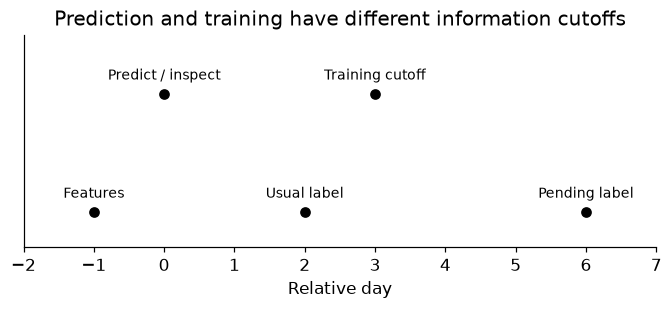

In [2]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge,LogisticRegression
from scipy.special import expit
N=600;X=rng.uniform(0,1,(N,2));nominal_train=np.arange(360);development=np.arange(360,480);final=np.arange(480,600)
feature_arrival=np.full(N,-1);label_arrival=np.full(N,2);label_arrival[:12]=6
train=nominal_train[label_arrival[nominal_train]<=3]
ledger=pd.DataFrame([['load and temperature',-1,True],['post-inspection report',1,False]],columns=['field','arrival_day','available_at_prediction_day_0']);display(ledger)
assert len(train)==348 and not np.any(label_arrival[train]>3)
assert np.all(feature_arrival<=0) and not ledger.available_at_prediction_day_0.iloc[1]
assert not set(train)&set(development) and not set(train)&set(final)
assert not set(development)&set(final)
fig,ax=plt.subplots(figsize=(6,2.7));events=[(-1,'Features'),(0,'Predict / inspect'),(2,'Usual label'),(3,'Training cutoff'),(6,'Pending label')]
for i,(day,label) in enumerate(events):ax.plot(day,i%2,'ko');ax.text(day,i%2+.12,label,ha='center',fontsize=9)
ax.set(xlim=(-2,7),ylim=(-.3,1.5),xlabel='Relative day',yticks=[],title='Prediction and training have different information cutoffs');plt.show()


<a id="formulations"></a>
## Fit the requested output type

Continuous response: .2+1.5*load+.15*temperature plus Gaussian noise sd .08 mm. Binary inspection finding is a separate Bernoulli draw with probability sigmoid(-2+3*load+.8*temperature). It is not the thresholded continuous response. A structured two-component output represents toy measured displacement components: [1.2*load+.2*temperature, .1*load+.7*temperature] mm plus independent .04 mm noise. Shared row identity makes this a vector output, but a multi-output ridge fit does not enforce physical equilibrium or rotations.

Fixed controls: StandardScaler then Ridge(alpha=1) for scalar/vector regression; StandardScaler then LogisticRegression(C=1,solver='lbfgs',max_iter=1000) for classification. The scaler fits training cases only. There is no hyperparameter search. Constant baselines use the training response mean, training finding rate and training mean vector.


Development regression RMSE [mm]: 0.07450610349086938


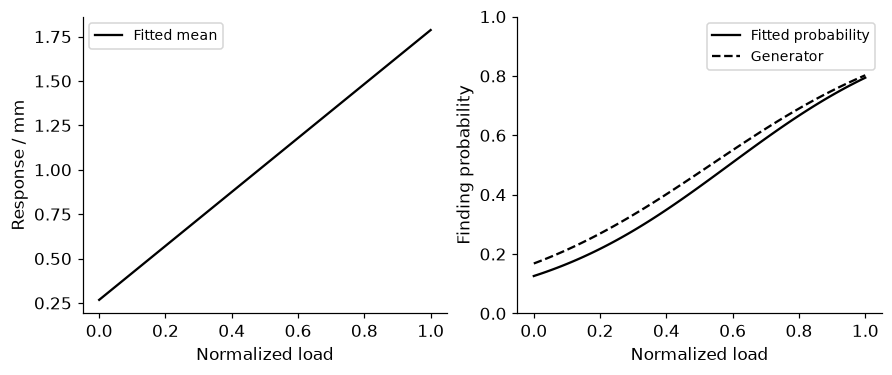

In [3]:
y=.2+1.5*X[:,0]+.15*X[:,1]+rng.normal(0,.08,N)
true_p=expit(-2+3*X[:,0]+.8*X[:,1]);finding=rng.binomial(1,true_p)
vector=np.column_stack([1.2*X[:,0]+.2*X[:,1],.1*X[:,0]+.7*X[:,1]])+rng.normal(0,.04,(N,2))
reg=make_pipeline(StandardScaler(),Ridge(alpha=1.)).fit(X[train],y[train])
clf=make_pipeline(StandardScaler(),LogisticRegression(C=1.,solver='lbfgs',max_iter=1000)).fit(X[train],finding[train])
structured=make_pipeline(StandardScaler(),Ridge(alpha=1.)).fit(X[train],vector[train])
assert np.allclose(reg[0].mean_,X[train].mean(0))
assert reg.predict(X[development]).shape==(120,)
assert clf.predict_proba(X[development]).shape==(120,2)
assert structured.predict(X[development]).shape==(120,2)
assert clf[-1].n_iter_[0]<1000
print('Development regression RMSE [mm]:',np.sqrt(np.mean((reg.predict(X[development])-y[development])**2)))
line=np.column_stack([np.linspace(0,1,100),np.full(100,.5)])
fig,axes=plt.subplots(1,2,figsize=(8,3.3));axes[0].plot(line[:,0],reg.predict(line),'k-',label='Fitted mean');axes[0].set(xlabel='Normalized load',ylabel='Response / mm');axes[0].legend(fontsize=9)
axes[1].plot(line[:,0],clf.predict_proba(line)[:,1],'k-',label='Fitted probability');axes[1].plot(line[:,0],expit(-2+3*line[:,0]+.4),'k--',label='Generator');axes[1].set(xlabel='Normalized load',ylabel='Finding probability',ylim=(0,1));axes[1].legend(fontsize=9);plt.show()


<a id="final"></a>
## Open final outcomes after all rules are fixed

Use RMSE in mm for regression, dimensionless log loss for binary probabilities and root mean squared Euclidean vector error in mm for structured prediction. These quantities answer different questions and cannot be ranked against one another. The vector metric sums component squared errors per member before averaging. The outcome meanings and baselines are fixed before this cell.


In [4]:
p=np.clip(clf.predict_proba(X[final])[:,1],1e-12,1-1e-12);base_p=float(finding[train].mean())
logloss=lambda yy,pp:float(-np.mean(yy*np.log(pp)+(1-yy)*np.log1p(-pp)))
results={'regression_RMSE_mm':float(np.sqrt(np.mean((reg.predict(X[final])-y[final])**2))),
'regression_baseline_RMSE_mm':float(np.sqrt(np.mean((y[train].mean()-y[final])**2))),
'finding_log_loss':logloss(finding[final],p),'finding_baseline_log_loss':logloss(finding[final],base_p),
'vector_RMSE_mm':float(np.sqrt(np.mean(np.sum((structured.predict(X[final])-vector[final])**2,axis=1)))),
'vector_baseline_RMSE_mm':float(np.sqrt(np.mean(np.sum((vector[train].mean(0)-vector[final])**2,axis=1))))}
assert np.isfinite(list(results.values())).all() and np.all((p>0)&(p<1))
RESULTS.update(results);RESULTS['eligible_training_labels']=len(train);print(results)


{'regression_RMSE_mm': 0.07861441637108232, 'regression_baseline_RMSE_mm': 0.4200415493552509, 'finding_log_loss': 0.6637549140005726, 'finding_baseline_log_loss': 0.6948490362764715, 'vector_RMSE_mm': 0.05666914032888592, 'vector_baseline_RMSE_mm': 0.3955109881694723}


<a id="exercises"></a>
## Exercises and hints

1. Make label delays depend on finding severity. Explain why complete-case training can change the represented population; do not relabel pending cases as negatives.
2. Add repeated buildings and future inspections. Specify group/time boundaries before fitting.
3. Predict a displacement field with boundary conditions. Distinguish output shape, loss and structural constraints.
4. Change a classification decision threshold using development costs, while preserving probability assessment and fresh final evidence.

**Hints:** supervision is the supplied input–target relationship, not a particular architecture. Select a formulation from target meaning and observation process. See official [supervised learning](https://scikit-learn.org/1.9/supervised_learning.html) and [multi-output methods](https://scikit-learn.org/1.9/modules/multiclass.html) documentation. Check row IDs, arrival times, target shape and metric units before model controls.


In [5]:
summary={'example_id':'code_027','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['label and feature availability', 'regression classification and vector outputs', 'training-only fitted state', 'label eligibility and independent assessment', 'output-specific baselines and metrics'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["label and feature availability", "regression classification and vector outputs", "training-only fitted state", "label eligibility and independent assessment", "output-specific baselines and metrics"], "elapsed_seconds": 0.244, "example_id": "code_027", "hardware": "Darwin arm64 CPU", "results": {"eligible_training_labels": 348, "finding_baseline_log_loss": 0.6948490362764715, "finding_log_loss": 0.6637549140005726, "regression_RMSE_mm": 0.07861441637108232, "regression_baseline_RMSE_mm": 0.4200415493552509, "vector_RMSE_mm": 0.05666914032888592, "vector_baseline_RMSE_mm": 0.3955109881694723}, "seed": 627, "versions": {"matplotlib": "3.11.0", "numpy": "2.4.4", "pandas": "3.0.3", "python": "3.14.3", "scikit-learn": "1.9.0", "scipy": "1.17.1"}}
